## Block 0 - Import Libraries

This section imports the libraries needed for data processing and bracket prediction.

In [1]:
# Block 0 - Import Libraries

import pandas as pd
import numpy as np

## Block 1 - Load 2026 Team Statistics

This section loads the 2026 season team statistics from the scraped web dataset.

In [2]:
# Block 1 - Load 2026 Team Statistics

cbb = pd.read_csv("2026 Regular Season Raw Data.csv")
cbb.head()

,RK,TEAM,CONF,G,W,ADJOE,ADJDE,BARTHAG,EFG_O,EFG_D,...,DRB,FTR,FTRD,2P_O,2P_D,3P_O,3P_D,ADJ_T,WAB,SEED
0,1,Duke,ACC,34,32,128.2,90.8,0.9813,56.8,46.2,...,24.8,37.8,23.7,60.1,46.6,35.1,30.4,65.8,13.7,1.0
1,2,Michigan,B10,34,31,127.6,91.0,0.9799,58.1,44.7,...,27.7,37.7,26.3,61.0,44.3,36.0,30.2,71.2,14.0,1.0
2,3,Arizona,B12,34,32,126.9,91.4,0.9776,55.1,45.0,...,26.9,42.9,27.7,55.4,43.8,36.0,31.4,70.0,13.7,1.0
3,4,Florida,SEC,33,26,126.1,92.3,0.9732,53.5,46.3,...,24.8,39.1,34.0,57.9,45.2,30.8,32.4,70.4,8.5,1.0
4,5,Houston,B12,34,28,125.4,92.4,0.9709,52.1,46.6,...,30.9,26.9,39.0,51.9,45.5,34.9,32.1,63.3,9.0,2.0


## Block 2 - Select and Rename Required Features

This section extracts the statistics needed by the model and renames them to match the expected schema.

In [3]:
# Block 2 - Select and Rename Required Features

team_avg = cbb[[
    "TEAM",
    "EFG_O",
    "TOR",
    "ORB",
    "FTR"
]].copy()

team_avg = team_avg.rename(columns={
    "TEAM": "TeamName",
    "EFG_O": "eFG",
    "TOR": "TOV",
    "ORB": "ORB",
    "FTR": "FTR"
})

team_avg.head()

,TeamName,eFG,TOV,ORB,FTR
0,Duke,56.8,15.7,38.1,37.8
1,Michigan,58.1,16.7,35.4,37.7
2,Arizona,55.1,15.1,38.1,42.9
3,Florida,53.5,16.5,43.2,39.1
4,Houston,52.1,13.0,35.9,26.9


## Block 3 - Create Team Lookup Dictionary

This section creates a lookup dictionary so the model can access team statistics by team name.

In [4]:
# Block 3 - Create Team Lookup Dictionary

team_lookup = team_avg.set_index("TeamName").to_dict("index")
list(team_lookup.keys())[:10]

['Duke',
 'Michigan',
 'Arizona',
 'Florida',
 'Houston',
 'Illinois',
 'Iowa St.',
 'Purdue',
 'Connecticut',
 'Vanderbilt']

## Block 4 - Normalize Team Names

This section fixes differences between bracket team names and dataset team names.

In [5]:
# Block 4 - Normalize Team Names

name_map = {
    "UConn": "Connecticut",
    "Ohio St.": "Ohio St.",
    "Michigan St.": "Michigan St.",
    "Miami (FL)": "Miami FL",
    "Miami (Ohio)": "Miami OH",
    "Queens (N.C.)": "Queens",
    "McNeese": "McNeese St.",
    "Saint Mary's": "Saint Mary's",
    "Iowa St.": "Iowa St.",
    "Cal Baptist": "Cal Baptist",
    "North Dakota St.": "North Dakota St.",
    "Prairie View A&M": "Prairie View A&M",
    "Long Island": "LIU"
}

def normalize_team_name(name):
    return name_map.get(name, name)

In [6]:
# Block 4.1 - Find Similar Team Names

def find_team_candidates(text):
    text = text.lower()
    matches = [team for team in team_lookup.keys() if text in team.lower()]
    print(matches)

## Block 5 - Check Team Names

This section checks whether a team name exists in the dataset after normalization.

In [7]:
# Block 5 - Check Team Names

def check_team(name):
    normalized = normalize_team_name(name)
    if normalized in team_lookup:
        print(f"{name} -> {normalized} -> FOUND")
    else:
        print(f"{name} -> {normalized} -> NOT FOUND")

## Block 6 - Predict Winner by Team Name

This section predicts the winner of a matchup using the selected 2026 team statistics.

In [8]:
# Block 6 - Predict Winner by Team Name

def predict_team_by_name(teamA_name, teamB_name):
    teamA_name = normalize_team_name(teamA_name)
    teamB_name = normalize_team_name(teamB_name)

    teamA = team_lookup[teamA_name]
    teamB = team_lookup[teamB_name]

    diff_eFG = teamA["eFG"] - teamB["eFG"]
    diff_TOV = teamA["TOV"] - teamB["TOV"]
    diff_ORB = teamA["ORB"] - teamB["ORB"]
    diff_FTR = teamA["FTR"] - teamB["FTR"]

    score = (
        0.08 * diff_eFG
        - 0.06 * diff_TOV
        + 0.05 * diff_ORB
        + 0.04 * diff_FTR
    )

    return teamA_name if score > 0 else teamB_name

## Block 7 - Predict Matchup Probabilities

This section outputs the predicted probabilities for both teams in a matchup.

In [9]:
# Block 7 - Predict Matchup Probabilities

def predict_with_probability(teamA_name, teamB_name):
    original_teamA = teamA_name
    original_teamB = teamB_name

    teamA_name = normalize_team_name(teamA_name)
    teamB_name = normalize_team_name(teamB_name)

    teamA = team_lookup[teamA_name]
    teamB = team_lookup[teamB_name]

    diff_eFG = teamA["eFG"] - teamB["eFG"]
    diff_TOV = teamA["TOV"] - teamB["TOV"]
    diff_ORB = teamA["ORB"] - teamB["ORB"]
    diff_FTR = teamA["FTR"] - teamB["FTR"]

    score = (
        0.08 * diff_eFG
        - 0.06 * diff_TOV
        + 0.05 * diff_ORB
        + 0.04 * diff_FTR
    )

    probA = 1 / (1 + np.exp(-score))

    return {
        original_teamA: round(float(probA * 100), 1),
        original_teamB: round(float((1 - probA) * 100), 1)
    }

## Block 8 - Define the 2026 Round of 64 Matchups

This section stores the official first-round tournament matchups.

In [10]:
# Block 8 - Define the 2026 Round of 64 Matchups

east_round1 = [
    ("Duke", "Siena"),
    ("Ohio St.", "TCU"),
    ("St. John's", "Northern Iowa"),
    ("Kansas", "Cal Baptist"),
    ("Louisville", "South Florida"),
    ("Michigan St.", "North Dakota St."),
    ("UCLA", "UCF"),
    ("UConn", "Furman")
]

west_round1 = [
    ("Arizona", "Long Island"),
    ("Villanova", "Utah St."),
    ("Wisconsin", "High Point"),
    ("Arkansas", "Hawaii"),
    ("BYU", "Texas"),
    ("Gonzaga", "Kennesaw St."),
    ("Miami (FL)", "Missouri"),
    ("Purdue", "Queens (N.C.)")
]

south_round1 = [
    ("Florida", "Prairie View A&M"),
    ("Clemson", "Iowa"),
    ("Vanderbilt", "McNeese"),
    ("Nebraska", "Troy"),
    ("North Carolina", "VCU"),
    ("Illinois", "Penn"),
    ("Saint Mary's", "Texas A&M"),
    ("Houston", "Idaho")
]

midwest_round1 = [
    ("Michigan", "Howard"),
    ("Georgia", "Saint Louis"),
    ("Texas Tech", "Akron"),
    ("Alabama", "Hofstra"),
    ("Tennessee", "Miami (Ohio)"),
    ("Virginia", "Wright St."),
    ("Kentucky", "Santa Clara"),
    ("Iowa St.", "Tennessee St.")
]

## Block 9 - Bracket Simulation Functions

This section contains the helper functions used to simulate each round of the tournament.
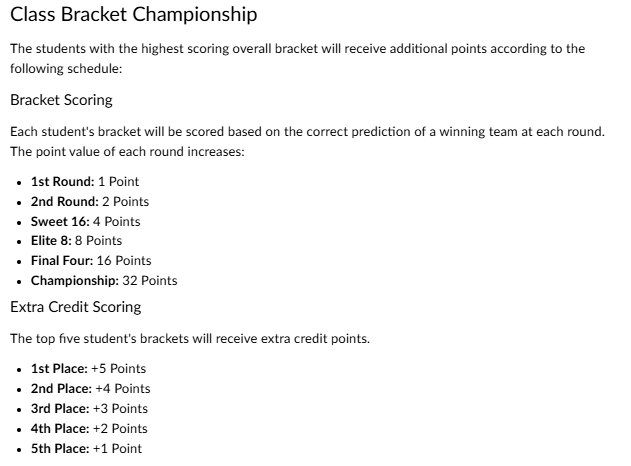

In [11]:
# Block 9 - Bracket Simulation Functions

mat_rows = []

def record_matchup(teamA, teamB):
    original_teamA = teamA
    original_teamB = teamB

    teamA = normalize_team_name(teamA)
    teamB = normalize_team_name(teamB)

    A = team_lookup[teamA]
    B = team_lookup[teamB]

    row = {
        "TeamA": original_teamA,
        "TeamB": original_teamB,
        "Diff_eFG": A["eFG"] - B["eFG"],
        "Diff_TOV": A["TOV"] - B["TOV"],
        "Diff_ORB": A["ORB"] - B["ORB"],
        "Diff_FTR": A["FTR"] - B["FTR"]
    }

    mat_rows.append(row)

def print_round(title, matchups):
    print(f"\n{title}")
    print("-" * 50)
    for teamA, teamB in matchups:
        record_matchup(teamA, teamB)
        probs = predict_with_probability(teamA, teamB)
        winner = predict_team_by_name(teamA, teamB)
        print(f"{teamA} vs {teamB} -> {winner} | {probs}")

def get_round_winners(matchups):
    return [predict_team_by_name(teamA, teamB) for teamA, teamB in matchups]

def pair_next_round(winners):
    return [(winners[i], winners[i + 1]) for i in range(0, len(winners), 2)]

def simulate_region(region_name, round1_matchups):
    print(f"\n\n========== {region_name} REGION ==========")

    print_round("Round of 64", round1_matchups)
    r64_winners = get_round_winners(round1_matchups)

    round32 = pair_next_round(r64_winners)
    print_round("Round of 32", round32)
    r32_winners = get_round_winners(round32)

    sweet16 = pair_next_round(r32_winners)
    print_round("Sweet 16", sweet16)
    s16_winners = get_round_winners(sweet16)

    elite8 = pair_next_round(s16_winners)
    print_round("Elite 8", elite8)
    e8_winners = get_round_winners(elite8)

    champion = e8_winners[0]
    print(f"\n{region_name} Champion: {champion}")

    return champion

## Block 10 - Run the Full Tournament

This section simulates all four regions, the Final Four, and the national championship.

In [12]:
# Block 10 - Run the Full Tournament

mat_rows = []

east_champ = simulate_region("East", east_round1)
west_champ = simulate_region("West", west_round1)
south_champ = simulate_region("South", south_round1)
midwest_champ = simulate_region("Midwest", midwest_round1)

final_four = [
    (east_champ, west_champ),
    (south_champ, midwest_champ)
]

print("\n\n========== FINAL FOUR ==========")
print_round("Final Four", final_four)
ff_winners = get_round_winners(final_four)

championship = [(ff_winners[0], ff_winners[1])]

print("\n\n========== NATIONAL CHAMPIONSHIP ==========")
print_round("Championship", championship)
national_champion = get_round_winners(championship)[0]

print(f"\nNATIONAL CHAMPION: {national_champion}")



========== East REGION ==========

Round of 64
--------------------------------------------------
Duke vs Siena -> Duke | {'Duke': 72.5, 'Siena': 27.5}
Ohio St. vs TCU -> Ohio St. | {'Ohio St.': 55.9, 'TCU': 44.1}
St. John's vs Northern Iowa -> St. John's | {"St. John's": 74.7, 'Northern Iowa': 25.3}
Kansas vs Cal Baptist -> Cal Baptist | {'Kansas': 46.0, 'Cal Baptist': 54.0}
Louisville vs South Florida -> South Florida | {'Louisville': 45.0, 'South Florida': 55.0}
Michigan St. vs North Dakota St. -> Michigan St. | {'Michigan St.': 59.7, 'North Dakota St.': 40.3}
UCLA vs UCF -> UCLA | {'UCLA': 53.8, 'UCF': 46.2}
UConn vs Furman -> Connecticut | {'UConn': 56.2, 'Furman': 43.8}

Round of 32
--------------------------------------------------
Duke vs Ohio St. -> Duke | {'Duke': 59.2, 'Ohio St.': 40.8}
St. John's vs Cal Baptist -> St. John's | {"St. John's": 63.0, 'Cal Baptist': 37.0}
South Florida vs Michigan St. -> South Florida | {'South Florida': 52.0, 'Michigan St.': 48.0}
UCLA vs Co

## Block 11 - Save Frequency Table

This section saves the generated matchup analytical table as a CSV file. The table includes the differential features used by the model for each simulated tournament matchup.

In [13]:
# Block 11 - Save Frequency Table (Project 4 structure)

mat_df = pd.DataFrame(mat_rows)

# Add predicted winner column (Win_A format)
mat_df["Win_A"] = [
    1 if predict_team_by_name(a, b) == normalize_team_name(a) else 0
    for a, b in zip(mat_df["TeamA"], mat_df["TeamB"])
]

mat_df.to_csv("FrequencyTable.csv", index=False)

mat_df.head()

,TeamA,TeamB,Diff_eFG,Diff_TOV,Diff_ORB,Diff_FTR,Win_A
0,Duke,Siena,6.2,-0.3,6.2,3.6,1
1,Ohio St.,TCU,5.6,-0.1,-3.6,-0.9,1
2,St. John's,Northern Iowa,-3.2,0.1,13.9,16.2,1
3,Kansas,Cal Baptist,3.0,-2.6,-8.3,-3.5,0
4,Louisville,South Florida,5.5,1.2,-5.3,-7.6,0
